# GENESIS results
AFR, AMR, EUR n = 2252

##### Modules

In [105]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import font_manager

##### Fonts & Colors

In [26]:
# font style
locations = ['/home/eger/software/fonts']
font_files = font_manager.findSystemFonts(fontpaths = locations)
for file in font_files:
    font_manager.fontManager.addfont(file)
plt.rcParams['font.family'] = 'Aptos'

# font size
title_size = 24
label_size = 18
tick_size = 16

anc_color_dict = {'EUR': 'dodgerblue', 'AMR': 'green', 'AFR': 'purple'}

##### Inputs

In [43]:
np.random.seed(42)
prefix = 'hgdp_1kg.AFR_AMR_EUR.auto.geno001.maf005.hwe10-5.pruned'

DIR0 = '/home/eger/references/gnomad/resources/hgdp_1kg'
DIR1 = '/scratch/eger/projects/hgdp_1kg/GENESIS_v2'

pop_list = os.path.join(DIR0, 'hgdp1kgp_pop.txt')

# pcair outputs
pcs = os.path.join(DIR1, prefix+'_pcair_PCs.txt')
varprop = os.path.join(DIR1, prefix+'_pcair_varprop.txt')
unrels = os.path.join(DIR1, prefix+'_pcair_unrels.txt')

In [5]:
### read in files ###
df0 = pd.read_csv(pop_list, sep='\t')

df1 = pd.read_csv(pcs, header=None, sep='\s+')
df1.columns = ['IID'] + ['PC'+str(i) for i in np.arange(1, df1.shape[1])]
df1 = df0.merge(df1, on=['IID'], how='inner')

varprop_dict = dict(zip(['PC'+str(i) for i in np.arange(1, df1.shape[1])],
                        pd.read_csv(varprop)['varprop']))
unrels_ids = list(pd.read_csv(unrels, header=None)[0])

df1 = df1[df1['IID'].isin(unrels_ids)]

In [30]:
print(len(unrels_ids))

1704


## PC-AiR

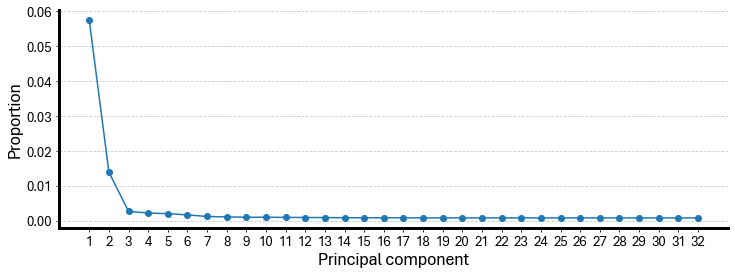

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

ax.plot(np.arange(1, len(varprop_dict)+1), varprop_dict.values(), zorder=3)
ax.scatter(np.arange(1, len(varprop_dict)+1), varprop_dict.values(), zorder=3)

#ax.set_ylim(0, 0.01)
ax.tick_params(axis='both', labelsize=14)
ax.set_xticks(np.arange(1, len(varprop_dict)+1))
ax.set_xlabel('Principal component', fontsize=18)
ax.set_ylabel('Proportion', fontsize=18)

plt.show()

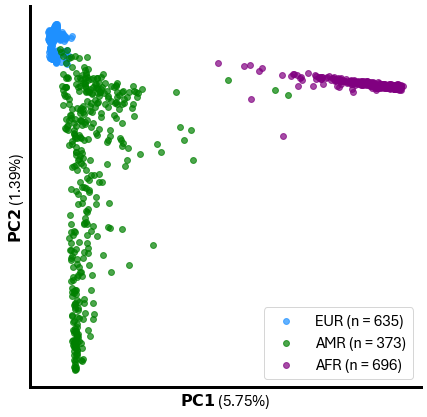

In [126]:
x_var = 'PC1'
y_var = 'PC2'

super_pops = anc_color_dict.keys()

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

for pop in super_pops:
    ax.scatter(df1[df1['Superpopulation'] == pop][x_var], 
               df1[df1['Superpopulation'] == pop][y_var], 
               label=pop+' (n = '+str(df1[df1['Superpopulation'] == pop].shape[0])+')', 
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    

#ax.set_xlim(-(df1[x_var].abs().max() + 0.1), df1[x_var].abs().max() + 0.1)
#ax.set_ylim(-(df1[y_var].abs().max() + 0.1), df1[y_var].abs().max() + 0.1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=16)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=16)
ax.legend(loc='lower right', fontsize=16)

plt.show()

Need to exclude the admixed individuals.

### AFR subset

In [9]:
afr_pops = sorted(df1[df1['Superpopulation'] == 'AFR'].Population.unique())
print(afr_pops)

['African Ancestry SW', 'African Caribbean', 'Bantu Kenya', 'Bantu South Africa', 'Biaka', 'Esan', 'Gambian Mandinka', 'Luhya', 'Mandenka', 'Mbuti', 'Mende', 'San', 'Yoruba']


In [10]:
west_afr_pops = ['Esan', 'Gambian Mandinka', 'Mandenka', 'Mende', 'Yoruba']
ref_afr_IIDs = list(df1[df1['Population'].isin(west_afr_pops)]['IID'])
print('West Africa n =', len(ref_afr_IIDs))

West Africa n = 435


In [33]:
df1[df1['Population'].isin(west_afr_pops)].Population.value_counts()

Yoruba              133
Gambian Mandinka    113
Esan                 97
Mende                78
Mandenka             14
Name: Population, dtype: int64

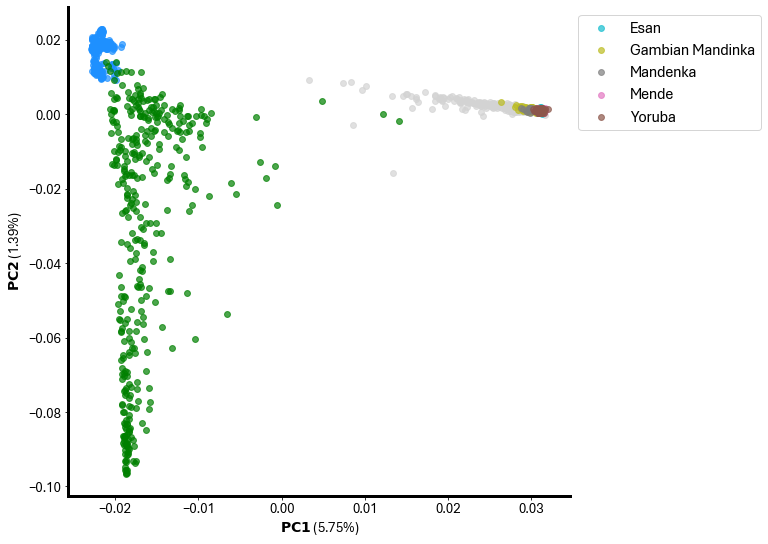

In [40]:
x_var = 'PC1'
y_var = 'PC2'

plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.tab10.colors)[::-1]
fig, ax = plt.subplots(figsize=(9, 9))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

for pop in ['EUR', 'AMR']:
    ax.scatter(df1[df1['Superpopulation'] == pop][x_var], 
               df1[df1['Superpopulation'] == pop][y_var], 
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    

ax.scatter(df1[(df1['Superpopulation'] == 'AFR') & (~df1['IID'].isin(ref_afr_IIDs))][x_var], 
           df1[(df1['Superpopulation'] == 'AFR') & (~df1['IID'].isin(ref_afr_IIDs))][y_var], 
           color='lightgray',
           s=35, alpha=0.7, zorder=3)   

for pop in west_afr_pops:
    ax.scatter(df1[df1['Population'] == pop][x_var], 
               df1[df1['Population'] == pop][y_var], 
               label=pop,
               s=35, alpha=0.7, zorder=3)    

ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=14)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=14)
ax.legend(bbox_to_anchor=(1, 1), fontsize=16)

plt.show()

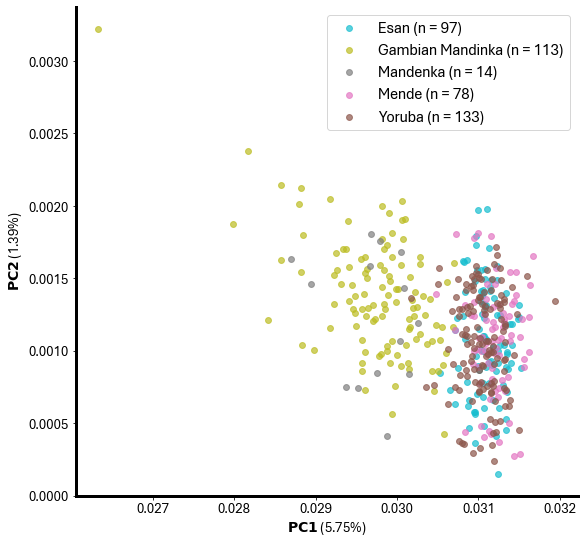

In [44]:
x_var = 'PC1'
y_var = 'PC2'

plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.tab10.colors)[::-1]
fig, ax = plt.subplots(figsize=(9, 9))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

for pop in west_afr_pops:
    ax.scatter(df1[df1['Population'] == pop][x_var], 
               df1[df1['Population'] == pop][y_var], 
               label=pop+' (n = '+str(df1[df1['Population'] == pop].shape[0])+')', 
               s=35, alpha=0.7, zorder=3)    

ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=14)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=14)
ax.legend(bbox_to_anchor=(1, 1), fontsize=16)

plt.show()

#### Downsampled AFR

In [57]:
sampling_strategy = {
    'Yoruba': 35,           
    'Esan': 35,             
    'Mende': 15,            
    'Gambian Mandinka': 10, 
    'Mandenka': 10
}
print(sum(sampling_strategy.values()))

105


In [62]:
ref_afr_dwnsmp_IIDs = []

# Apply the sampling strategy to each population
for pop, sample_size in sampling_strategy.items():
    # Get all samples from this population
    pop_samples = df1[df1['Population'] == pop]
    
    # Randomly select the specified number of samples
    selected_indices = np.random.choice(pop_samples.index, size=sample_size, replace=False)
    selected_samples = list(pop_samples.loc[selected_indices, 'IID'])
    
    ref_afr_dwnsmp_IIDs += selected_samples
print(len(ref_afr_dwnsmp_IIDs))

105


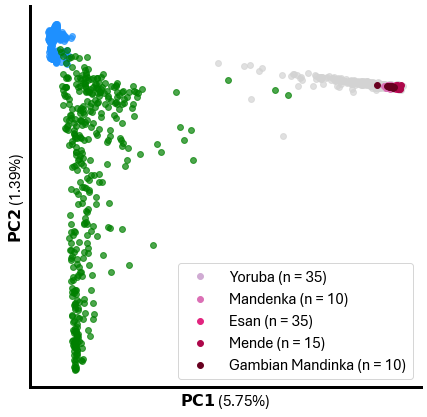

In [118]:
x_var = 'PC1'
y_var = 'PC2'

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

for pop in ['EUR', 'AMR']:
    ax.scatter(df1[df1['Superpopulation'] == pop][x_var], 
               df1[df1['Superpopulation'] == pop][y_var], 
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    

ax.scatter(df1[(df1['Superpopulation'] == 'AFR') & (~df1['IID'].isin(ref_afr_dwnsmp_IIDs))][x_var], 
           df1[(df1['Superpopulation'] == 'AFR') & (~df1['IID'].isin(ref_afr_dwnsmp_IIDs))][y_var], 
           color='lightgray',
           s=35, alpha=0.7, zorder=3)   

pops = df1[df1['IID'].isin(ref_afr_dwnsmp_IIDs)]['Population'].unique()
cmap = plt.cm.get_cmap('PuRd')
cmap_colors = cmap(np.linspace(0.3, 1, len(pops)))

for i, pop in enumerate(pops):
    df = df1[(df1['Population'] == pop) & (df1['IID'].isin(ref_afr_dwnsmp_IIDs))]
    ax.scatter(df[x_var], df[y_var], color=cmap_colors[i],
            label=pop+' (n = '+str(df.shape[0])+')', 
           s=35, alpha=1, zorder=3)  

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=16)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=16)
ax.legend(loc='lower right', fontsize=16)

plt.show()

### AMR subset

In [12]:
amr_pops = sorted(df1[df1['Superpopulation'] == 'AMR'].Population.unique())
print(amr_pops)

['Colombian', 'Karitiana', 'Maya', 'Mexican Ancestry', 'Peruvian', 'Pima', 'Puerto Rican', 'Surui']


In [13]:
hgdp_amr_IIDs = list(df1[(df1['Population'].isin(
                    ['Colombian', 'Karitiana', 'Pima', 'Surui', 'Maya'])) & 
                    (df1['IID'].str.contains('HGDP'))]['IID'])
print('HGDP AMR n =', len(hgdp_amr_IIDs))

HGDP AMR n = 31


In [16]:
# get PC1 and PC2 value thresholds
hgdp_amr_PC1_thres = df1[df1['IID'].isin(hgdp_amr_IIDs)]['PC1'].max()
hgdp_amr_PC2_thres = df1[df1['IID'].isin(hgdp_amr_IIDs)]['PC2'].max()

other_amr_IIDs = list(df1[(~df1['IID'].isin(hgdp_amr_IIDs)) &
                    (df1['PC1'] <= hgdp_amr_PC1_thres) &
                    (df1['PC2'] <= hgdp_amr_PC2_thres)]['IID'])
print('1000G AMR n =', len(other_amr_IIDs))

1000G AMR n = 68


In [17]:
ref_amr_IIDs = sorted(set(hgdp_amr_IIDs) | set(other_amr_IIDs))
print('AMR n =', len(ref_amr_IIDs))

AMR n = 99


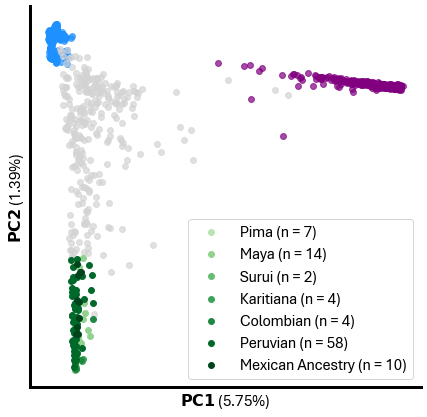

In [111]:
x_var = 'PC1'
y_var = 'PC2'

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

for pop in ['EUR', 'AFR']:
    ax.scatter(df1[df1['Superpopulation'] == pop][x_var], 
               df1[df1['Superpopulation'] == pop][y_var], 
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    

ax.scatter(df1[(df1['Superpopulation'] == 'AMR') & (~df1['IID'].isin(ref_amr_IIDs))][x_var], 
           df1[(df1['Superpopulation'] == 'AMR') & (~df1['IID'].isin(ref_amr_IIDs))][y_var], 
           color='lightgray',
           s=35, alpha=0.7, zorder=3)   

pops = df1[df1['IID'].isin(ref_amr_IIDs)]['Population'].unique()
cmap = plt.cm.get_cmap('Greens')
cmap_colors = cmap(np.linspace(0.3, 1, len(pops)))

for i, pop in enumerate(pops):
    df = df1[(df1['Population'] == pop) & (df1['IID'].isin(ref_amr_IIDs))]
    ax.scatter(df[x_var], df[y_var], color=cmap_colors[i],
            label=pop+' (n = '+str(df.shape[0])+')', 
           s=35, alpha=1, zorder=3)  

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=16)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=16)
ax.legend(loc='lower right', fontsize=16)

plt.show()

## EUR subset

In [19]:
eur_pops = sorted(df1[df1['Superpopulation'] == 'EUR'].Population.unique())
eur_pops

['Adygei',
 'Basque',
 'Bergamo Italian',
 'British',
 'CEPH',
 'Finnish',
 'French',
 'Iberian',
 'Orcadian',
 'Russian',
 'Sardinian',
 'Toscani',
 'Tuscan']

In [20]:
south_eur_pops = ['Basque', 'Bergamo Italian', 'French', 'Iberian', 'Toscani', 'Tuscan']
ref_eur_IIDs = list(df1[df1['Population'].isin(south_eur_pops)]['IID'])
print('EUR n =', len(ref_eur_IIDs))

EUR n = 264


In [63]:
df1[df1['Population'].isin(south_eur_pops)]['Population'].value_counts()

Iberian            103
Toscani            101
French              24
Basque              21
Bergamo Italian      9
Tuscan               6
Name: Population, dtype: int64

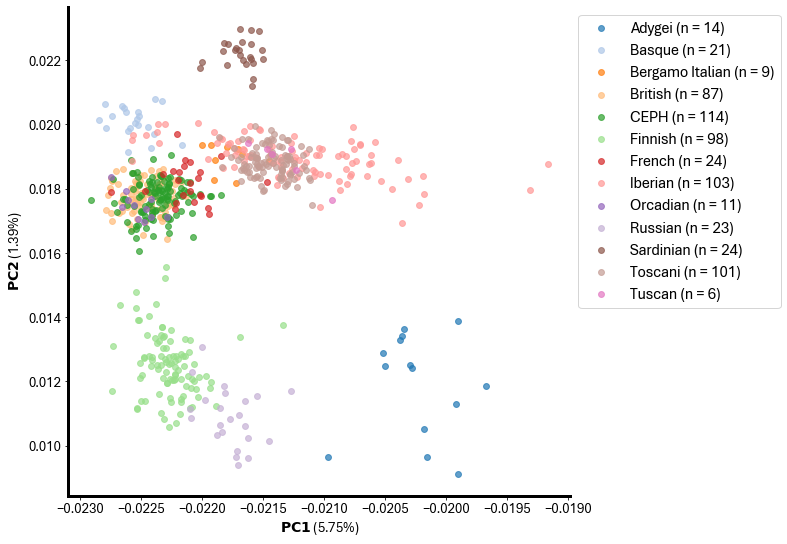

In [65]:
x_var = 'PC1'
y_var = 'PC2'

plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.tab20.colors)
fig, ax = plt.subplots(figsize=(9, 9))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

# for pop in ['EUR', 'AMR']:
#     ax.scatter(df1[df1['Superpopulation'] == pop][x_var], 
#                df1[df1['Superpopulation'] == pop][y_var], 
#                color='lightgray',
#                s=35, alpha=0.7, zorder=3)    

for pop in eur_pops:
    ax.scatter(df1[df1['Population'] == pop][x_var], 
               df1[df1['Population'] == pop][y_var], 
               label=pop+' (n = '+str(df1[df1['Population'] == pop].shape[0])+')', 
               s=35, alpha=0.7, zorder=3)    

ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=14)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=14)
ax.legend(bbox_to_anchor=(1, 1), fontsize=16)

plt.show()

#### Downsample EUR

In [66]:
sampling_strategy = {
    'Iberian': 50,          # Primary Spanish ancestry source - highest priority
    'Basque': 20,           # Important Iberian component
    'French': 15,           # Secondary Southern European source
    'Toscani': 15,          # Representative Mediterranean population
    'Bergamo Italian': 5,   # Keep most samples but still downsample
    'Tuscan': 0             # Exclude as Toscani already represents Tuscan ancestry
}
print(sum(sampling_strategy.values()))

105


In [67]:
ref_eur_dwnsmp_IIDs = []

# Apply the sampling strategy to each population
for pop, sample_size in sampling_strategy.items():
    # Get all samples from this population
    pop_samples = df1[df1['Population'] == pop]
    
    # Randomly select the specified number of samples
    selected_indices = np.random.choice(pop_samples.index, size=sample_size, replace=False)
    selected_samples = list(pop_samples.loc[selected_indices, 'IID'])
    
    ref_eur_dwnsmp_IIDs += selected_samples
print(len(ref_eur_dwnsmp_IIDs))

105


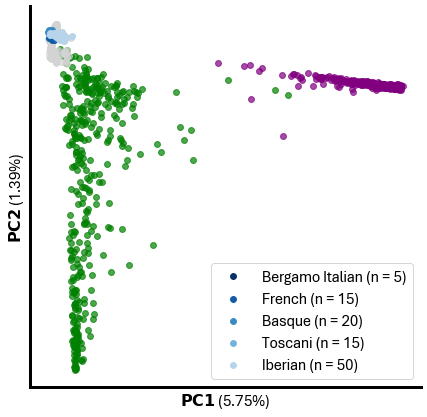

In [123]:
x_var = 'PC1'
y_var = 'PC2'

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

for pop in ['AFR', 'AMR']:
    ax.scatter(df1[df1['Superpopulation'] == pop][x_var], 
               df1[df1['Superpopulation'] == pop][y_var], 
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    

ax.scatter(df1[(df1['Superpopulation'] == 'EUR') & (~df1['IID'].isin(ref_eur_dwnsmp_IIDs))][x_var], 
           df1[(df1['Superpopulation'] == 'EUR') & (~df1['IID'].isin(ref_eur_dwnsmp_IIDs))][y_var], 
           color='lightgray',
           s=35, alpha=0.7, zorder=3)   

pops = df1[df1['IID'].isin(ref_eur_dwnsmp_IIDs)]['Population'].unique()
cmap = plt.cm.get_cmap('Blues')
cmap_colors = cmap(np.linspace(0.3, 1, len(pops)))[::-1]

for i, pop in enumerate(pops):
    df = df1[(df1['Population'] == pop) & (df1['IID'].isin(ref_eur_dwnsmp_IIDs))]
    ax.scatter(df[x_var], df[y_var], color=cmap_colors[i],
            label=pop+' (n = '+str(df.shape[0])+')', 
           s=35, alpha=1, zorder=3)  

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=16)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=16)
ax.legend(loc='lower right', fontsize=16)

plt.show()

## Panel sample map
AFR, AMR, EUR \
unrelated \
HGDP and 1000G only

In [22]:
print('AFR n =', len(ref_afr_IIDs))
print('AMR n =', len(ref_amr_IIDs))
print('EUR n =', len(ref_eur_IIDs))

AFR n = 435
AMR n = 99
EUR n = 264


In [23]:
sample_map = os.path.join(DIR1, 'hgdp_1kg.AFR_AMR_EUR_unrelated_samplemap.txt')

df2 = df1[df1['IID'].isin(ref_afr_IIDs + ref_amr_IIDs + ref_eur_IIDs)]
df2[['IID', 'Superpopulation']].to_csv(sample_map, sep='\t', header=False, index=False)

print(df2.shape[0])
print(sample_map)

798
/scratch/eger/projects/hgdp_1kg/GENESIS_v2/hgdp_1kg.AFR_AMR_EUR_unrelated_samplemap.txt


In [25]:
df2['FID'] = 0
keep = os.path.join(DIR1, 'hgdp_1kg.AFR_AMR_EUR_unrelated_sampleIDs.txt')

df2[['FID', 'IID']].to_csv(keep, sep='\t', header=False, index=False)

/tmp/ipykernel_248280/71732943.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['FID'] = 0


## Second panel with equal numbers of samples per reference population

In [68]:
print('AFR n =', len(ref_afr_dwnsmp_IIDs))
print('AMR n =', len(ref_amr_IIDs))
print('EUR n =', len(ref_eur_dwnsmp_IIDs))

AFR n = 105
AMR n = 99
EUR n = 105


In [69]:
sample_map = os.path.join(DIR1, 'hgdp_1kg.AFR_AMR_EUR_unrelated_downsampled_samplemap.txt')

df2 = df1[df1['IID'].isin(ref_afr_dwnsmp_IIDs + ref_amr_IIDs + ref_eur_dwnsmp_IIDs)]
df2[['IID', 'Superpopulation']].to_csv(sample_map, sep='\t', header=False, index=False)

print(df2.shape[0])
print(sample_map)

309
/scratch/eger/projects/hgdp_1kg/GENESIS_v2/hgdp_1kg.AFR_AMR_EUR_unrelated_downsampled_samplemap.txt


In [70]:
df2['FID'] = 0
keep = os.path.join(DIR1, 'hgdp_1kg.AFR_AMR_EUR_unrelated_downsampled_sampleIDs.txt')

df2[['FID', 'IID']].to_csv(keep, sep='\t', header=False, index=False)

/tmp/ipykernel_248280/856124502.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['FID'] = 0


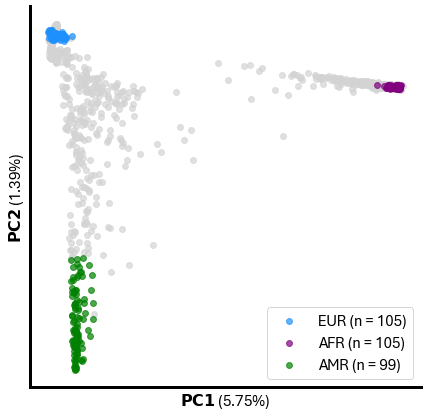

In [125]:
x_var = 'PC1'
y_var = 'PC2'

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.tick_params(axis='both', labelsize=14)

pop_dict = {'EUR': ref_eur_dwnsmp_IIDs, 
            'AFR': ref_afr_dwnsmp_IIDs, 
            'AMR': ref_amr_IIDs}
for pop,ids in pop_dict.items():
    # included
    ax.scatter(df1[(df1['Superpopulation'] == pop) & (df1['IID'].isin(ids))][x_var], 
               df1[(df1['Superpopulation'] == pop) & (df1['IID'].isin(ids))][y_var], 
               label=pop+' (n = '+str(df1[(df1['Superpopulation'] == pop) & (df1['IID'].isin(ids))].shape[0])+')',
               color=anc_color_dict[pop],
               s=35, alpha=0.7, zorder=3)    
    # excluded
    ax.scatter(df1[(df1['Superpopulation'] == pop) & (~df1['IID'].isin(ids))][x_var], 
               df1[(df1['Superpopulation'] == pop) & (~df1['IID'].isin(ids))][y_var], 
               color='lightgray',
               s=35, alpha=0.7, zorder=2)    

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(f'$\mathbf{{PC1}}$ ({varprop_dict[x_var]*100:.2f}%)', fontsize=16)
ax.set_ylabel(f'$\mathbf{{PC2}}$ ({varprop_dict[y_var]*100:.2f}%)', fontsize=16)
ax.legend(loc='lower right', fontsize=16)

plt.show()